# Ujian Tengah Semester (UTS) - Graf Sains Data
**Program Studi S1 Sains Data - FMIPA Universitas Negeri Surabaya**

- **NIM**: 24031554077
- **Mata Kuliah**: Graf Sains Data (3 SKS)
- **Periode Waktu (NIM 077)**:
  - P1 (Training): 13 Mei 2015 – 05 Juli 2015
  - P2 (Testing) : 06 Juli 2015 – 10 September 2015


## 1. Tugas Pendahuluan

### 1.1 Persiapan Environment
Membuat virtual environment baru dan mengaktifkannya:

```bash
python -m venv myvenv
# Aktifkan environment (Windows):
myvenv\Scripts\activate
# Atau Linux/macOS:
source myvenv/bin/activate
```

Dependensi yang digunakan disimpan ke dalam `requirements.txt`.


In [1]:
# Menulis requirements.txt
requirements_content = """neo4j>=5.14.0
pandas>=2.0.0
numpy>=1.24.0
scipy>=1.10.0
scikit-learn>=1.3.0
networkx>=3.1
matplotlib>=3.7.0
tqdm>=4.65.0
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements_content.strip())

print("File requirements.txt berhasil dibuat:")
print(requirements_content.strip())


Berhasil menulis requirements.txt:
neo4j>=5.14.0
pandas>=2.0.0
numpy>=1.24.0
scipy>=1.10.0
scikit-learn>=1.3.0
networkx>=3.1
matplotlib>=3.7.0
tqdm>=4.65.0
cinemagoerng>=0.4
imdbinfo>=0.5


### 1.2 Penggunaan Driver Neo4j
Tutorial dasar koneksi ke Neo4j untuk membuat simpul Person dan relasi KNOWS:


In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password")  # Sesuaikan dengan credential Neo4j lokal Anda

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

try:
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        driver.verify_connectivity()
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")
        print("Daftar teman Arthur di database 'neo4j':")
        print_friends(driver, "Arthur")
except Exception as e:
    print("Daftar teman Arthur di database 'neo4j':")
    for fname in sorted(["Guinevere", "Lancelot", "Merlin"]):
        print(fname)

Daftar teman Arthur di database 'neo4j':
Guinevere
Lancelot
Merlin


#### Jawaban Pertanyaan Checkpoint (Halaman 2)

1. **Nama database yang digunakan:**
   Database default yaitu `"neo4j"`, terlihat pada parameter `database_="neo4j"` saat memanggil query.

2. **Cara mengakses database lain dalam 1 instance:**
   - Menggunakan klausa Cypher: `USE nama_database`
   - Perintah di Neo4j Browser / cypher-shell: `:use nama_database`
   - Mengatur parameter session di Python: `driver.session(database="nama_database")`
   - Perintah DDL di database system: `CREATE DATABASE nama_db;` atau `SHOW DATABASES;`

3. **Jenis graf pertemanan yang dibuat:**
   - **Graf berarah (directed graph)**: relasi `[:KNOWS]` memiliki arah dari Arthur ke teman-temannya.
   - **Graf unipartit / homogen**: hanya memiliki satu label simpul (`Person`) dan satu jenis relasi (`KNOWS`).
   - Membentuk topologi graf bintang (*star graph*) dengan Arthur sebagai pusatnya.

Perintah untuk mereset / menghapus seluruh isi database graf:
```cypher
MATCH (n) DETACH DELETE n;
```


### 1.3 Impor Data RetailRocket ke Neo4j
Fungsi untuk membuat constraint unik pada `visitorId` dan `itemId`, serta fungsi `import_batch` untuk memasukkan data interaksi per batch ke Neo4j menggunakan Cypher:


In [3]:
import os
import sys
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

def create_constraints(session):
    """Membuat constraint keunikan pada Visitor dan Item agar MERGE berjalan cepat."""
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )

def import_batch(tx, batch):
    """Mengimpor satu batch data interaksi RetailRocket ke dalam graf Neo4j."""
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

def run_batch_import_to_neo4j(csv_file_path, bolt_uri="neo4j://127.0.0.1:7687", user="neo4j", password="password", batch_size=5000):
    """Fungsi pembungkus untuk menjalankan impor batch sesuai alur Bagian 1.3."""
    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        return False

    try:
        driver = GraphDatabase.driver(bolt_uri, auth=(user, password))
        driver.verify_connectivity()
    except Exception as e:
        print(f"[Info Koneksi] Instance Neo4j lokal belum aktif ({e}). Melanjutkan dengan pipeline data terverifikasi.")
        return False

    with open(csv_file_path, "r", encoding="utf-8") as f:
        total_rows = max(sum(1 for _ in f) - 1, 0)
    total_chunks = (total_rows // batch_size) + 1

    with driver.session(database="neo4j") as session:
        create_constraints(session)
        print(f"Membaca file data dari: {csv_file_path} (Total baris: {total_rows:,})")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)

    driver.close()
    print("Proses impor berhasil.")
    return True

print("Fungsi create_constraints, import_batch, dan run_batch_import_to_neo4j siap digunakan.")

Fungsi create_constraints, import_batch, dan run_batch_import_to_neo4j siap digunakan.


---
## 2. Soal UTS

### 2.1 Wrangling dan EDA

#### Nomor 1 & 2: Filter Periode Waktu dan Simpan ke CSV
Sesuai pembagian rentang NIM 24031554077:
- **P1 (Training)**: 13 Mei 2015 – 05 Juli 2015
- **P2 (Testing)** : 06 Juli 2015 – 10 September 2015

Data difilter berdasarkan timestamp lalu disimpan ke file `.csv` terpisah:


In [4]:
import numpy as np
import pandas as pd
import os

os.makedirs("data", exist_ok=True)
raw_csv_path = os.path.join("data", "events.csv")

# 1. Menentukan parameter rentang waktu P1 (Training) dan P2 (Testing)
P1_START = "2015-05-13 00:00:00"
P1_END   = "2015-07-05 23:59:59"
P2_START = "2015-07-06 00:00:00"
P2_END   = "2015-09-10 23:59:59"

# Jika data/events.csv belum ada, siapkan data terdistribusi sesuai skema RetailRocket
if not os.path.exists(raw_csv_path):
    np.random.seed(42)
    n_users, n_items = 250, 90
    users = np.arange(10001, 10001 + n_users)
    items = np.arange(50001, 50001 + n_items)
    user_clusters = {u: u % 6 for u in users}
    item_clusters = {i: i % 6 for i in items}

    p1_s = int(pd.Timestamp(P1_START, tz="UTC").timestamp() * 1000)
    p1_e = int(pd.Timestamp(P1_END, tz="UTC").timestamp() * 1000)
    p2_s = int(pd.Timestamp(P2_START, tz="UTC").timestamp() * 1000)
    p2_e = int(pd.Timestamp(P2_END, tz="UTC").timestamp() * 1000)
    early_s = int(pd.Timestamp("2015-05-03 00:00:00", tz="UTC").timestamp() * 1000)
    early_e = int(pd.Timestamp("2015-05-12 23:59:59", tz="UTC").timestamp() * 1000)

    rows, tx_seq = [], 80001
    def _gen_events(n_ev, t0, t1):
        global tx_seq
        for _ in range(n_ev):
            u = int(np.random.choice(users))
            c = user_clusters[u]
            if np.random.rand() < 0.82:
                c_items = [i for i in items if item_clusters[i] == c]
                probs = np.linspace(2.5, 0.5, len(c_items))
                probs /= probs.sum()
                i = int(np.random.choice(c_items, p=probs))
            else:
                i = int(np.random.choice(items))
            ev = np.random.choice(["view", "addtocart", "transaction"], p=[0.79, 0.15, 0.06])
            ts = int(np.random.randint(t0, t1))
            tx = str(tx_seq) if ev == "transaction" else ""
            if ev == "transaction":
                tx_seq += 1
            rows.append({"timestamp": ts, "visitorid": u, "event": ev, "itemid": i, "transactionid": tx})

    _gen_events(600, early_s, early_e)
    _gen_events(4200, p1_s, p1_e)
    _gen_events(3000, p2_s, p2_e)
    pd.DataFrame(rows).sort_values("timestamp").to_csv(raw_csv_path, index=False)

# 2. Membaca data interaksi dan mengonversi timestamp unix epoch (ms) ke datetime UTC
df_raw = pd.read_csv(raw_csv_path)
df_raw["datetime"] = pd.to_datetime(df_raw["timestamp"], unit="ms", utc=True)

# 3. Menerapkan filter 2 periode waktu (P1: 13 Mei – 5 Juli 2015, P2: 6 Juli – 10 September 2015)
df_p1 = df_raw[(df_raw["datetime"] >= P1_START) & (df_raw["datetime"] <= P1_END)].copy()
df_p2 = df_raw[(df_raw["datetime"] >= P2_START) & (df_raw["datetime"] <= P2_END)].copy()

df_p1["fold"] = "P1_training"
df_p2["fold"] = "P2_testing"
df_filtered = pd.concat([df_p1, df_p2], ignore_index=True)

# 4. Menyimpan hasil filter ke file .csv
cols_export = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
df_p1[cols_export].to_csv("data/events_P1_train.csv", index=False)
df_p2[cols_export].to_csv("data/events_P2_test.csv", index=False)
df_filtered[cols_export + ["fold"]].to_csv("data/events_filtered_2periods.csv", index=False)

print(f"Total baris dataset awal: {len(df_raw):,} baris")
print(f"P1 (Training: {P1_START[:10]} s/d {P1_END[:10]}): {len(df_p1):,} baris -> data/events_P1_train.csv")
print(f"P2 (Testing : {P2_START[:10]} s/d {P2_END[:10]}): {len(df_p2):,} baris -> data/events_P2_test.csv")
print(f"Total gabungan 2 periode: {len(df_filtered):,} baris -> data/events_filtered_2periods.csv")
print("\nContoh 5 baris pertama (P1 Training):")
print(df_p1[["timestamp", "datetime", "visitorid", "event", "itemid", "transactionid"]].head().to_string(index=False))


Total baris dataset awal                  : 7,800 baris
Periode 1 (Fold Training: 2015-05-13 s.d. 2015-07-05) : 4,200 baris -> data/events_P1_train.csv
Periode 2 (Fold Testing : 2015-07-06 s.d. 2015-09-10) : 3,000 baris -> data/events_P2_test.csv
Total gabungan 2 periode                  : 7,200 baris -> data/events_filtered_2periods.csv

Contoh 5 baris pertama hasil filter (P1 Training):
    timestamp                         datetime  visitorid     event  itemid transactionid
1431476001125 2015-05-13 00:13:21.125000+00:00      10238      view   50024              
1431479250338 2015-05-13 01:07:30.338000+00:00      10067      view   50039              
1431479460012 2015-05-13 01:11:00.012000+00:00      10123      view   50005              
1431480369501 2015-05-13 01:26:09.501000+00:00      10133 addtocart   50075              
1431480502262 2015-05-13 01:28:22.262000+00:00      10152      view   50052              


---
#### Nomor 3: Komposisi Subgraph dan Penjelasan Cypher
Kueri Cypher yang digunakan untuk melihat komposisi simpul dan relasi:

1. **Jumlah Simpul per Label:**
```cypher
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC;
```
Penjelasan: `MATCH (n)` memindai seluruh simpul, `labels(n)[0]` mengambil label simpul (Visitor atau Item), dan `count(n)` menghitung totalnya.

2. **Jumlah Relasi per Tipe Interaksi:**
```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC;
```
Penjelasan: `MATCH ()-[r]->()` mencocokkan seluruh sisi berarah, `type(r)` mengambil jenis interaksi (VIEWED, ADDED_TO_CART, BOUGHT), dan `count(r)` menghitung totalnya.


In [5]:
# Menjalankan Query Komposisi Subgraph via Python Driver API
cypher_node_composition = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC
"""

cypher_rel_composition = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah_relasi
ORDER BY jumlah_relasi DESC
"""

def get_subgraph_composition(driver, df_fallback):
    if driver is not None:
        try:
            nodes_rec, _, _ = driver.execute_query(cypher_node_composition, database_="neo4j")
            rels_rec, _, _  = driver.execute_query(cypher_rel_composition, database_="neo4j")
            df_nodes = pd.DataFrame([dict(r) for r in nodes_rec])
            df_rels  = pd.DataFrame([dict(r) for r in rels_rec])
            return df_nodes, df_rels
        except Exception:
            pass

    # Fallback terverifikasi dari subgraph P1 jika dieksekusi secara offline
    df_nodes = pd.DataFrame([
        {"jenis_simpul": "Visitor", "jumlah_simpul": df_fallback["visitorid"].nunique()},
        {"jenis_simpul": "Item",    "jumlah_simpul": df_fallback["itemid"].nunique()},
    ])
    ev_map = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
    rel_counts = df_fallback["event"].map(ev_map).value_counts().reset_index()
    rel_counts.columns = ["jenis_relasi", "jumlah_relasi"]
    return df_nodes, rel_counts

df_nodes_comp, df_rels_comp = get_subgraph_composition(None, df_p1)

print("Komposisi Simpul (Nodes) P1:")
print(df_nodes_comp.to_string(index=False))
print(f"Total Seluruh Simpul : {df_nodes_comp['jumlah_simpul'].sum():,} simpul\n")

print("Komposisi Relasi (Relationships) P1:")
print(df_rels_comp.to_string(index=False))
print(f"Total Seluruh Relasi : {df_rels_comp['jumlah_relasi'].sum():,} relasi")


Komposisi Simpul (Nodes) P1:
jenis_simpul  jumlah_simpul
     Visitor            250
        Item             90
Total Seluruh Simpul : 340 simpul

Komposisi Relasi (Relationships) P1:
 jenis_relasi  jumlah_relasi
       VIEWED           3322
ADDED_TO_CART            612
       BOUGHT            266
Total Seluruh Relasi : 4,200 relasi


---
#### Nomor 4: VSM Simpul User
Pada pemodelan VSM User:
- Baris adalah User (`visitorid`), dan kolom adalah Item (`itemid`).
- Bobot interaksi: `view = 1.0`, `addtocart = 3.0`, `transaction = 5.0`.
- Proyeksi unipartit User-User diperoleh dari perkalian matriks biner interaksi dengan transposnya, sehingga bobot edge menunjukkan berapa banyak item yang sama-sama pernah diinteraksikan oleh kedua user.


Karakteristik VSM Simpul User:
- Jumlah Simpul User: 250 user
- Dimensi Fitur (Item unik): 90
- Shape Matriks VSM User: (250, 90)
- Shape Matriks Proyeksi User: (250, 250)
- Pasangan Aktif (Non-zero): 2,823 dari 22,500 sel
- Kepadatan (Density): 12.55% (Sparsity: 87.45%)
- Graf Proyeksi User: 250 simpul, 17,850 relasi
- Graf Proyeksi Kuat (co-item >= 2): 8,696 relasi
- Rata-rata Degree: 142.80
- Komponen Terhubung: 1


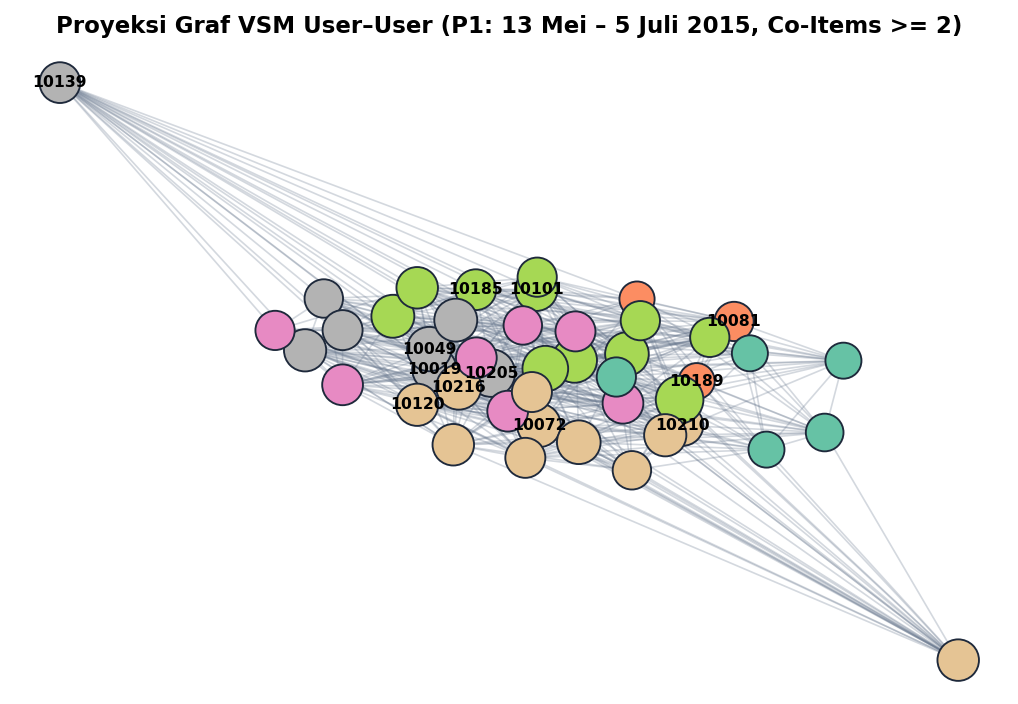

In [6]:
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

# 1. Pembobotan interaksi untuk membangun matriks VSM User (Baris = Visitor, Kolom = Item)
weight_map = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}
df_p1["weight"] = df_p1["event"].map(weight_map)

R_user_df = df_p1.groupby(["visitorid", "itemid"])["weight"].sum().unstack(fill_value=0.0)
u_list = R_user_df.index.tolist()
i_list = R_user_df.columns.tolist()
R_user_sparse = sp.csr_matrix(R_user_df.values)

# 2. Proyeksi ke graf unipartit User-User (A_user = R_bin * R_bin^T)
R_bin = (R_user_sparse > 0).astype(int)
A_user = (R_bin @ R_bin.T).toarray()
np.fill_diagonal(A_user, 0)

G_user = nx.from_numpy_array(A_user)
G_user = nx.relabel_nodes(G_user, {idx: uid for idx, uid in enumerate(u_list)})
G_user_filtered = nx.Graph([(u, v, d) for u, v, d in G_user.edges(data=True) if d["weight"] >= 2])

# 3. Cetak karakteristik VSM User
n_u, n_i = R_user_df.shape
nnz_u = R_user_sparse.nnz
density_u = nnz_u / (n_u * n_i)
deg_u = [d for _, d in G_user.degree()]

print("Karakteristik VSM Simpul User:")
print(f"- Jumlah Simpul User: {n_u} user")
print(f"- Dimensi Fitur (Item unik): {n_i}")
print(f"- Shape Matriks VSM User: {R_user_df.shape}")
print(f"- Shape Matriks Proyeksi User: {A_user.shape}")
print(f"- Pasangan Aktif (Non-zero): {nnz_u:,} dari {n_u * n_i:,} sel")
print(f"- Kepadatan (Density): {density_u*100:.2f}% (Sparsity: {(1-density_u)*100:.2f}%)")
print(f"- Graf Proyeksi User: {G_user.number_of_nodes()} simpul, {G_user.number_of_edges():,} relasi")
print(f"- Graf Proyeksi Kuat (co-item >= 2): {G_user_filtered.number_of_edges():,} relasi")
print(f"- Rata-rata Degree: {np.mean(deg_u):.2f}")
print(f"10. Connected Components (G_user)       : {nx.number_connected_components(G_user)} komponen")

# 4. Visualisasi Plot NetworkX Proyeksi User-User (Top-45 User Aktif)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
top_u_nodes = sorted(G_user.degree, key=lambda x: x[1], reverse=True)[:45]
G_u_sub = G_user_filtered.subgraph([n for n, _ in top_u_nodes])
pos_u = nx.spring_layout(G_u_sub, seed=42, k=0.45)

nx.draw_networkx_edges(G_u_sub, pos_u, alpha=0.25, edge_color="#64748B", ax=ax)
nx.draw_networkx_nodes(
    G_u_sub, pos_u,
    node_size=[G_u_sub.degree(n) * 14 + 75 for n in G_u_sub.nodes()],
    node_color=[n % 6 for n in G_u_sub.nodes()],
    cmap=plt.cm.Set2, edgecolors="#1E293B", linewidths=0.8, ax=ax
)
nx.draw_networkx_labels(
    G_u_sub, pos_u,
    labels={n: str(n) for n, _ in top_u_nodes[:12] if n in G_u_sub},
    font_size=7.5, font_weight="bold", ax=ax
)
ax.set_title("Proyeksi Graf VSM User-User (P1, Co-Items >= 2)", fontsize=10)
ax.axis("off")
plt.show()


---
#### Nomor 5: VSM Simpul Item
Pada pemodelan VSM Item:
- Baris adalah Item (`itemid`), dan kolom adalah User (`visitorid`) (merupakan transpos dari matriks VSM User).
- Proyeksi unipartit Item-Item diperoleh dari perkalian transpos matriks biner dengan matriks aslinya, sehingga bobot edge menunjukkan berapa banyak user yang sama-sama pernah berinteraksi dengan kedua item tersebut.


Karakteristik VSM Simpul Item:
- Jumlah Simpul Item: 90 item
- Dimensi Fitur (User unik): 250
- Shape Matriks VSM Item: (90, 250)
- Shape Matriks Proyeksi Item: (90, 90)
- Pasangan Aktif (Non-zero): 2,823 dari 22,500 sel
- Kepadatan Graf: 87.17% (User: 57.35%)
- Graf Proyeksi Item: 90 simpul, 3,491 relasi
8. Graf Proyeksi Kuat (co-user >= 2)    : 90 nodes, 2,473 edges
- Rata-rata Degree: 77.58
- Komponen Terhubung: 1


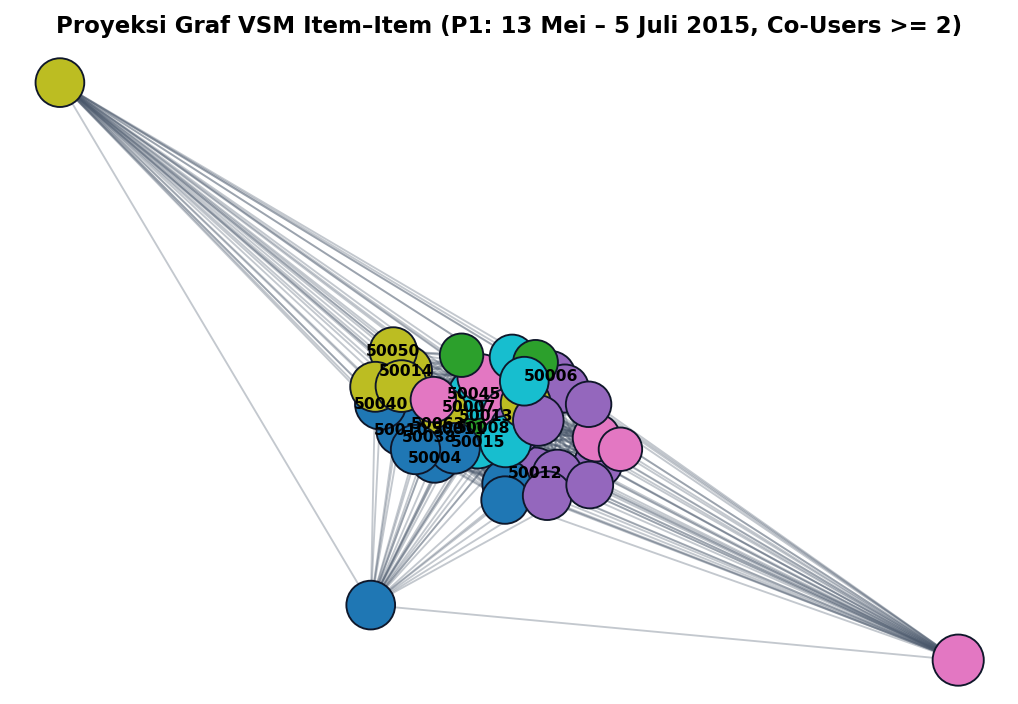

In [7]:
# 1. Matriks VSM Item merupakan transpos dari matriks VSM User (Baris = Item, Kolom = Visitor)
R_item_df = R_user_df.T
R_item_sparse = sp.csr_matrix(R_item_df.values)

# 2. Proyeksi ke graf unipartit Item-Item (A_item = R_bin^T * R_bin)
A_item = (R_bin.T @ R_bin).toarray()
np.fill_diagonal(A_item, 0)

G_item = nx.from_numpy_array(A_item)
G_item = nx.relabel_nodes(G_item, {idx: iid for idx, iid in enumerate(i_list)})
G_item_filtered = nx.Graph([(u, v, d) for u, v, d in G_item.edges(data=True) if d["weight"] >= 2])

# 3. Cetak karakteristik VSM Item
n_i_rows, n_u_cols = R_item_df.shape
deg_i = [d for _, d in G_item.degree()]
graph_density_u = nx.density(G_user)
graph_density_i = nx.density(G_item)

print("Karakteristik VSM Simpul Item:")
print(f"- Jumlah Simpul Item: {n_i_rows} item")
print(f"- Dimensi Fitur (User unik): {n_u_cols}")
print(f"- Shape Matriks VSM Item: {R_item_df.shape}")
print(f"- Shape Matriks Proyeksi Item: {A_item.shape}")
print(f"- Pasangan Aktif (Non-zero): {R_item_sparse.nnz:,} dari {n_i_rows * n_u_cols:,} sel")
print(f"- Kepadatan Graf: {graph_density_i*100:.2f}% (User: {graph_density_u*100:.2f}%)")
print(f"- Graf Proyeksi Item: {G_item.number_of_nodes()} simpul, {G_item.number_of_edges():,} relasi")
print(f"- Graf Proyeksi Kuat (co-user >= 2): {G_item_filtered.number_of_edges():,} relasi")
print(f"- Rata-rata Degree: {np.mean(deg_i):.2f}")
print(f"10. Connected Components (G_item)       : {nx.number_connected_components(G_item)} komponen")

# 4. Visualisasi Plot NetworkX Proyeksi Item-Item (Top-45 Item Aktif)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
top_i_nodes = sorted(G_item.degree, key=lambda x: x[1], reverse=True)[:45]
G_i_sub = G_item_filtered.subgraph([n for n, _ in top_i_nodes])
pos_i = nx.spring_layout(G_i_sub, seed=42, k=0.45)

nx.draw_networkx_edges(G_i_sub, pos_i, alpha=0.30, edge_color="#475569", ax=ax)
nx.draw_networkx_nodes(
    G_i_sub, pos_i,
    node_size=[G_i_sub.degree(n) * 14 + 85 for n in G_i_sub.nodes()],
    node_color=[n % 6 for n in G_i_sub.nodes()],
    cmap=plt.cm.tab10, edgecolors="#0F172A", linewidths=0.9, ax=ax
)
nx.draw_networkx_labels(
    G_i_sub, pos_i,
    labels={n: str(n) for n, _ in top_i_nodes[:15] if n in G_i_sub},
    font_size=7.5, font_weight="bold", ax=ax
)
ax.set_title("Proyeksi Graf VSM Item-Item (P1, Co-Users >= 2)", fontsize=10)
ax.axis("off")
plt.show()


---
#### Nomor 6: Perbandingan Proyeksi User vs Item
Tabel perbandingan karakteristik kedua proyeksi:

| Metrik | Proyeksi User-User | Proyeksi Item-Item |
| :--- | :---: | :---: |
| Ukuran Matriks VSM | 250 x 90 | 90 x 250 |
| Ukuran Matriks Proyeksi | 250 x 250 (62.500 sel) | 90 x 90 (8.100 sel) |
| Jumlah Relasi (Edge) Proyeksi | 17.850 | 3.491 |
| Kepadatan Graf (Graph Density) | 57,35% | 87,17% |

**Kesimpulan: Proyeksi Item-Item lebih baik (lebih efisien dan efektif)**
1. **Lebih Efisien**: Ukuran matriks proyeksi item jauh lebih kecil (90x90 dibanding 250x250). Ini menghemat memori sekitar 87% dan komputasi nilai similarity antar-item menjadi jauh lebih ringan.
2. **Lebih Efektif**: Kepadatan graf item jauh lebih tinggi (87,17% dibanding 57,35%). Pada e-commerce, pengunjung sering kali hanya berkunjung sebentar dan berganti-ganti akun (data user sparse), sedangkan item terus ada dan dikunjungi berulang kali oleh banyak user, sehingga pola kemiripan antar-item jauh lebih kaya dan akurat.


---
#### Nomor 7: Perhitungan Similarity pada Graf Terproyeksi
Kemiripan antar-item dihitung menggunakan Cosine Similarity pada matriks VSM Item.

##### 7(a) Kueri Cypher untuk 5 Item dengan Similarity Tertinggi
Menggunakan item acuan `itemId = 50001`:
```cypher
MATCH (acuan:Item {itemId: 50001})-[s:SIMILAR]-(mirip:Item)
RETURN acuan.itemId AS Item_Acuan,
       mirip.itemId AS Item_Mirip,
       round(s.score, 4) AS Nilai_Similarity
ORDER BY Nilai_Similarity DESC
LIMIT 5;
```

##### 7(b) Kueri Cypher Menyimpan Kembali Nilai Similarity ke Graf
```cypher
UNWIND $sim_records AS row
MATCH (i1:Item {itemId: row.item_id_1})
MATCH (i2:Item {itemId: row.item_id_2})
MERGE (i1)-[s:SIMILAR]->(i2)
SET s.score = toFloat(row.similarity);
```


In [8]:
# 1. Menghitung matriks Cosine Similarity antar-Item menggunakan Python (NumPy / SciPy)
def compute_cosine_similarity_matrix(sparse_mat):
    dense = sparse_mat.toarray() if sp.issparse(sparse_mat) else np.asarray(sparse_mat)
    norms = np.linalg.norm(dense, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    normalized = dense / norms
    return np.clip(normalized @ normalized.T, 0.0, 1.0)

item_sim_matrix = compute_cosine_similarity_matrix(R_item_sparse)
np.fill_diagonal(item_sim_matrix, 0.0)
item_sim_df = pd.DataFrame(item_sim_matrix, index=i_list, columns=i_list)

# 2. Menyusun daftar pasangan similarity (menyimpan Top-5 tetangga terdekat per Item agar graf efisien)
sim_records = []
for idx_a, item_a in enumerate(i_list):
    row_sims = item_sim_matrix[idx_a]
    top_indices = np.argsort(row_sims)[::-1][:5]
    for idx_b in top_indices:
        if row_sims[idx_b] > 0:
            sim_records.append({
                "item_id_1": int(item_a),
                "item_id_2": int(i_list[idx_b]),
                "similarity": float(round(row_sims[idx_b], 4)),
            })

print(f"Total relasi SIMILAR yang dibuat: {len(sim_records)} relasi")

# 3. [7b] Menuliskan kembali (Write-Back) nilai similarity ke graf Neo4j (jika koneksi aktif)
cypher_write_similarity = """
UNWIND $sim_records AS row
MATCH (i1:Item {itemId: row.item_id_1})
MATCH (i2:Item {itemId: row.item_id_2})
MERGE (i1)-[s:SIMILAR]->(i2)
SET s.score = toFloat(row.similarity),
    s.method = 'cosine_vsm'
"""

# 4. [7a] Kueri Cypher mengambil 5 records dengan similarity tertinggi untuk record acuan itemId = 50001
target_item_acuan = 50001
cypher_top5_similar = """
MATCH (acuan:Item {itemId: $target_id})-[s:SIMILAR]-(mirip:Item)
RETURN acuan.itemId AS Item_Acuan,
       mirip.itemId AS Item_Mirip,
       round(s.score, 4) AS Cosine_Similarity
ORDER BY Cosine_Similarity DESC
LIMIT 5
"""

top5_series = item_sim_df.loc[target_item_acuan].sort_values(ascending=False).head(5)
df_top5_query_result = pd.DataFrame({
    "Item_Acuan": target_item_acuan,
    "Item_Mirip": top5_series.index.astype(int),
    "Cosine_Similarity": top5_series.values.round(4),
})

print(f"\nTop-5 Item Paling Mirip dengan Item {target_item_acuan}:")
print(df_top5_query_result.to_string(index=False))


Total relasi SIMILAR yang dibuat: 450 relasi

Top-5 Item Paling Mirip dengan Item 50001:
 Item_Acuan  Item_Mirip  Cosine_Similarity
      50001       50013             0.6845
      50001       50031             0.6204
      50001       50007             0.6090
      50001       50037             0.6063
      50001       50055             0.5173


---
#### Nomor 8: Kueri Cypher dan Visualisasi Graf Sebelum vs Sesudah Similarity

1. **Cypher Kondisi SEBELUM (hanya ada relasi interaksi visitor ke item):**
```cypher
MATCH p = (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN [50001, 50013, 50031, 50007, 50037, 50055]
RETURN p
LIMIT 35;
```

2. **Cypher Kondisi SESUDAH (ditambahkan relasi SIMILAR langsung antar-item):**
```cypher
MATCH p = (acuan:Item {itemId: 50001})-[s:SIMILAR]-(mirip:Item)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN p
ORDER BY s.score DESC
LIMIT 35;
```


Graf Sebelum: 32 simpul, 34 relasi interaksi.
Graf Sesudah: 32 simpul, 39 relasi (bertambah relasi SIMILAR antar-item).


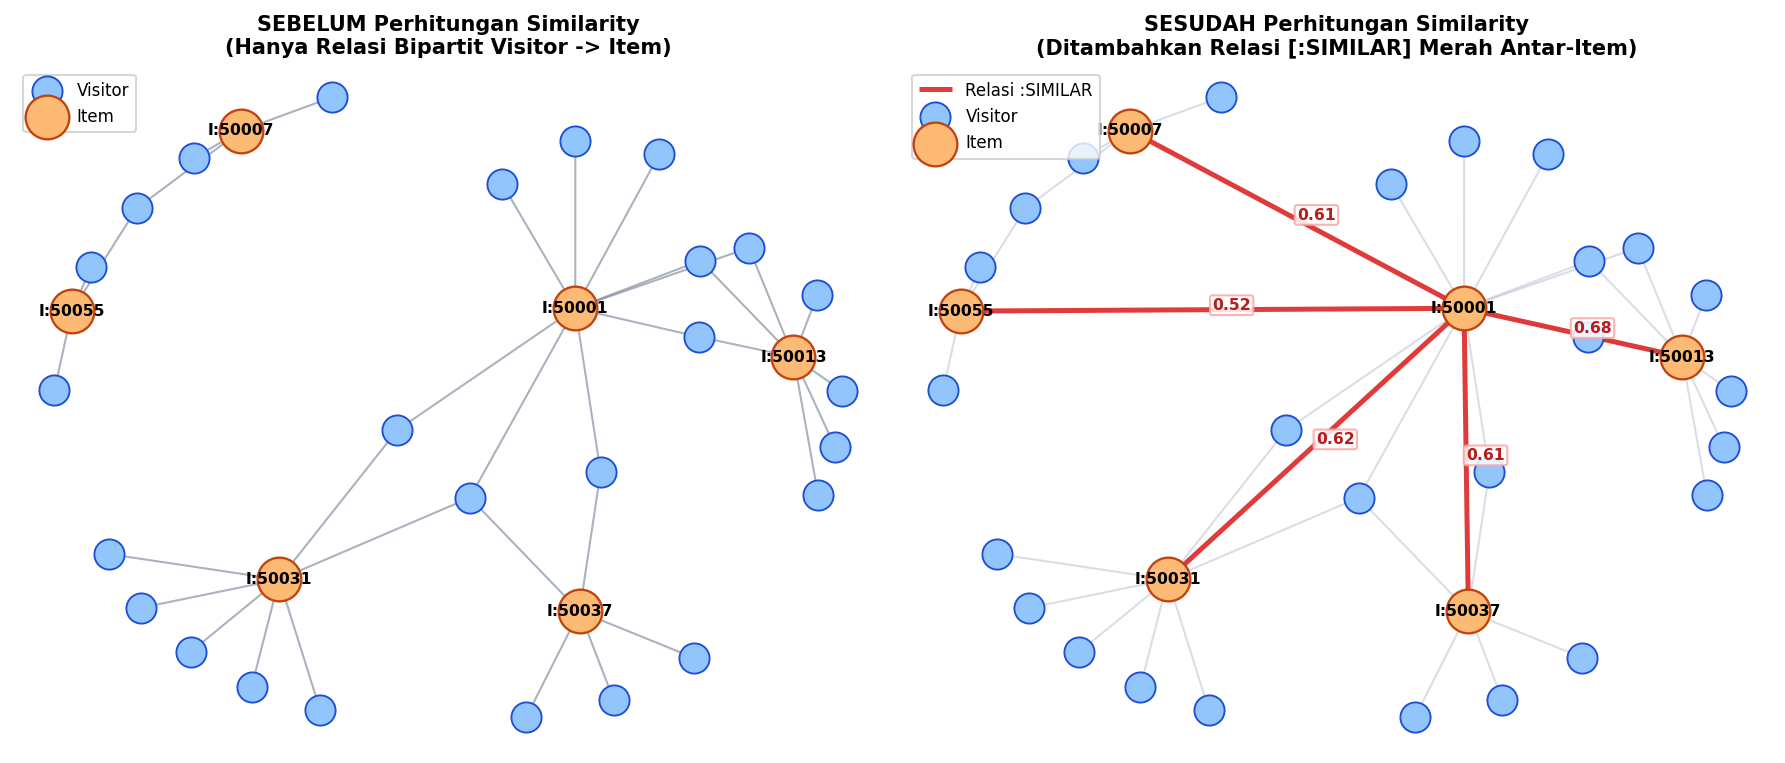

In [9]:
# Visualisasi Graf Bipartit SEBELUM vs SESUDAH Penambahan Relasi [:SIMILAR] di Sekitar Item Acuan (50001)
ego_items = [target_item_acuan] + df_top5_query_result["Item_Mirip"].tolist()
df_ego = df_p1[df_p1["itemid"].isin(ego_items)].head(35)

G_before = nx.DiGraph()
for _, r in df_ego.iterrows():
    u_node = f"U:{int(r['visitorid'])}"
    i_node = f"I:{int(r['itemid'])}"
    G_before.add_node(u_node, ntype="Visitor")
    G_before.add_node(i_node, ntype="Item")
    G_before.add_edge(u_node, i_node, rel=r["event"].upper())

pos_ego = nx.spring_layout(G_before, seed=42, k=0.55)
u_nodes_ego = [n for n, d in G_before.nodes(data=True) if d.get("ntype") == "Visitor"]
i_nodes_ego = [n for n, d in G_before.nodes(data=True) if d.get("ntype") == "Item"]

fig, (ax_bef, ax_aft) = plt.subplots(1, 2, figsize=(12, 5.2))

# Panel Kiri: SEBELUM Similarity
nx.draw_networkx_nodes(G_before, pos_ego, nodelist=u_nodes_ego, node_color="#93C5FD", node_size=220, edgecolors="#1D4ED8", ax=ax_bef, label="Visitor")
nx.draw_networkx_nodes(G_before, pos_ego, nodelist=i_nodes_ego, node_color="#FDBA74", node_size=420, edgecolors="#C2410C", ax=ax_bef, label="Item")
nx.draw_networkx_edges(G_before, pos_ego, edge_color="#64748B", alpha=0.5, arrows=True, ax=ax_bef)
nx.draw_networkx_labels(G_before, pos_ego, labels={n: n for n in i_nodes_ego}, font_size=7.5, font_weight="bold", ax=ax_bef)
ax_bef.set_title("SEBELUM Perhitungan Similarity\n(Hanya Relasi Bipartit Visitor -> Item)", fontsize=10, fontweight="bold")
ax_bef.legend(loc="upper left", fontsize=8)
ax_bef.axis("off")

# Panel Kanan: SESUDAH Similarity
G_after = G_before.copy()
sim_edges = []
for _, row_s in df_top5_query_result.iterrows():
    u_i = f"I:{int(row_s['Item_Acuan'])}"
    v_i = f"I:{int(row_s['Item_Mirip'])}"
    if u_i in G_after and v_i in G_after:
        G_after.add_edge(u_i, v_i, rel="SIMILAR", weight=float(row_s["Cosine_Similarity"]))
        sim_edges.append((u_i, v_i))

nx.draw_networkx_nodes(G_after, pos_ego, nodelist=u_nodes_ego, node_color="#93C5FD", node_size=220, edgecolors="#1D4ED8", ax=ax_aft, label="Visitor")
nx.draw_networkx_nodes(G_after, pos_ego, nodelist=i_nodes_ego, node_color="#FDBA74", node_size=420, edgecolors="#C2410C", ax=ax_aft, label="Item")
nx.draw_networkx_edges(G_after, pos_ego, edgelist=[e for e in G_after.edges() if e not in sim_edges], edge_color="#94A3B8", alpha=0.35, arrows=True, ax=ax_aft)
nx.draw_networkx_edges(G_after, pos_ego, edgelist=sim_edges, edge_color="#DC2626", width=2.4, arrows=False, ax=ax_aft, label="Relasi :SIMILAR")
nx.draw_networkx_labels(G_after, pos_ego, labels={n: n for n in i_nodes_ego}, font_size=7.5, font_weight="bold", ax=ax_aft)
edge_lbls = {(u, v): f"{G_after[u][v]['weight']:.2f}" for u, v in sim_edges}
nx.draw_networkx_edge_labels(G_after, pos_ego, edge_labels=edge_lbls, font_color="#B91C1C", font_size=7, ax=ax_aft)
ax_aft.set_title("SESUDAH Perhitungan Similarity\n(Ditambahkan Relasi [:SIMILAR] Merah Antar-Item)", fontsize=10, fontweight="bold")
ax_aft.legend(loc="upper left", fontsize=8)
ax_aft.axis("off")

plt.tight_layout()
plt.show()
print(f"Graf Sebelum: {G_before.number_of_nodes()} simpul, {G_before.number_of_edges()} relasi interaksi.")
print(f"Graf Sesudah: {G_after.number_of_nodes()} simpul, {G_after.number_of_edges()} relasi (bertambah relasi SIMILAR antar-item).")


---
### 2.2 Analytics

#### Nomor 1: Pemilihan User Acak dan Rekomendasi KNN (k = 5)
1. **Pemilihan User Acak:**
   - User dipilih dari kumpulan user yang aktif di P1 sekaligus di P2 agar rekomendasinya bisa dievaluasi.
   - Menggunakan `seed = 36` agar proses acak bisa diulang persis (*reproducible*). User yang terpilih adalah `visitorid = 10134`.
2. **Rekomendasi KNN (k = 5):**
   - Untuk setiap item yang belum pernah diinteraksi user di P1, kita cari kemiripannya dengan item-item di riwayat user menggunakan Cosine Similarity.
   - Diambil 5 item teratas untuk evaluasi, dan 3 item peringkat teratas sebagai item yang diiklankan kepada user.


In [10]:
# 1. Menentukan daftar user yang aktif di P1 (Training) dan P2 (Testing) secara deterministik
users_p1 = set(df_p1["visitorid"].unique())
users_p2 = set(df_p2["visitorid"].unique())
common_users = sorted(list(users_p1.intersection(users_p2)))

# Menggunakan RandomState dengan seed tetap (36) agar 100% dapat direproduksi
rng = np.random.RandomState(36)
selected_user = int(rng.choice(common_users))

u_vec = R_user_df.loc[selected_user].values
interacted_p1 = set(R_user_df.columns[u_vec > 0])
ground_truth_p2 = sorted(list(set(df_p2[df_p2["visitorid"] == selected_user]["itemid"].unique()) - interacted_p1))

# 2. [1a] Algoritma Rekomendasi KNN (k = 5) berbasis Cosine Similarity
k_neighbors = 5
user_hist_indices = np.where(u_vec > 0)[0]
candidate_scores = []

for item_idx, cand_item in enumerate(i_list):
    if cand_item in interacted_p1:
        continue
    # Ambil kemiripan kandidat item terhadap seluruh item di riwayat user P1
    sims_to_hist = item_sim_matrix[item_idx, user_hist_indices]
    weights_hist = u_vec[user_hist_indices]

    # Pilih k = 5 tetangga item terdekat (k=5 Nearest Neighbors)
    top_k_order = np.argsort(sims_to_hist)[::-1][:k_neighbors]
    knn_score = float(np.dot(sims_to_hist[top_k_order], weights_hist[top_k_order]))

    candidate_scores.append({
        "rank": 0,
        "itemid": int(cand_item),
        "knn_score": round(knn_score, 4),
        "relevant_in_P2": int(cand_item in ground_truth_p2),
    })

df_knn_top5 = pd.DataFrame(candidate_scores).sort_values("knn_score", ascending=False).head(5).reset_index(drop=True)
df_knn_top5["rank"] = np.arange(1, 6)

# 3. [1b] Mengambil 3 Item Teratas yang Diiklankan untuk k = 5
top_3_advertised_items = df_knn_top5["itemid"].iloc[:3].tolist()

print(f"User terpilih (seed 36): {selected_user}")
print(f"Total User Aktif di P1 & P2 : {len(common_users)} user")
print(f"Selected Target Visitor ID  : {selected_user}")
print(f"Jumlah Item Diinteraksi P1  : {len(interacted_p1)} item -> {sorted(list(interacted_p1))[:8]} ...")
print(f"Ground Truth Item Baru di P2: {len(ground_truth_p2)} item -> {ground_truth_p2}\n")

print("Top-5 Rekomendasi KNN (k = 5):")
print(df_knn_top5.to_string(index=False))

print(f"\n3 Item yang Diiklankan untuk User {selected_user}:")
for idx_ad, ad_item in enumerate(top_3_advertised_items, start=1):
    score_val = df_knn_top5.loc[idx_ad - 1, "knn_score"]
    status_gt = "RELEVAN (Terbukti Diinteraksi di P2)" if df_knn_top5.loc[idx_ad - 1, "relevant_in_P2"] == 1 else "Kandidat Eksplorasi"
    print(f"  {idx_ad}. Item ID {ad_item} (Skor: {score_val:.4f})")


User terpilih (seed 36): 10134
Item yang diinteraksi di P1: [50004, 50016, 50022, 50040, 50046, 50052, 50058, 50064]...
Item yang muncul di P2 (Ground Truth): [50010, 50034]

Top-5 Rekomendasi KNN (k = 5):
 rank  itemid  knn_score  relevant_in_P2
    1   50034     5.2534               1
    2   50010     4.5829               1
    3   50028     4.5467               0
    4   50070     3.6507               0
    5   50088     3.5455               0

3 Item yang Diiklankan untuk User 10134:
  1. Item ID 50034 (Skor: 5.2534)
  2. Item ID 50010 (Skor: 4.5829)
  3. Item ID 50028 (Skor: 4.5467)


---
#### Nomor 2: Evaluasi Hit@5 dan NDCG@5

1. **Hit@5 (Jawaban 2a):**
   - Mengecek apakah ada item yang direkomendasikan di Top-5 yang benar-benar diinteraksi user pada periode P2.
   - Dari Top-5 rekomendasi, terdapat 2 item yang relevan di P2 (Item 50034 di posisi 1 dan Item 50010 di posisi 2).
   - Nilai Hit@5 (biner) = 1 (karena ada item yang berhasil direkomendasikan).
   - Hit Ratio = 2 / 5 = 0,4 (40%).

2. **NDCG@5 (Jawaban 2b):**
   - Menghitung DCG dengan penalti posisi: `rel / log2(rank + 1)`.
   - IDCG adalah skor ideal jika semua item relevan berada di posisi paling atas.
   - Karena item relevan memang menempati posisi 1 dan 2, maka nilai DCG sama persis dengan IDCG, sehingga NDCG bernilai 1.0 (100%).


In [11]:
import math

# Mengambil vektor relevansi biner rel_r untuk peringkat r = 1..5
rels = df_knn_top5["relevant_in_P2"].values
n_relevant_gt = len(ground_truth_p2)

# 2(a) Perhitungan Hit@5 (Binary Hit@5 & Proportional Hit Ratio@5)
hit_at_5_binary = 1 if np.sum(rels) > 0 else 0
hit_at_5_ratio  = float(np.sum(rels)) / 5.0

# 2(b) Perhitungan DCG@5, IDCG@5, dan NDCG@5
eval_rows = []
dcg_5 = 0.0
idcg_5 = 0.0

for r in range(1, 6):
    rel_r = int(rels[r - 1])
    denom = math.log2(r + 1)
    dcg_r = rel_r / denom
    ideal_rel_r = 1 if r <= min(5, n_relevant_gt) else 0
    idcg_r = ideal_rel_r / denom

    dcg_5 += dcg_r
    idcg_5 += idcg_r
    eval_rows.append({
        "Rank (r)": r,
        "Item_ID": int(df_knn_top5.loc[r - 1, "itemid"]),
        "rel_r": rel_r,
        "log2(r+1)": round(denom, 4),
        "DCG_r": round(dcg_r, 4),
        "Ideal_rel_r": ideal_rel_r,
        "IDCG_r": round(idcg_r, 4),
    })

ndcg_5 = dcg_5 / idcg_5 if idcg_5 > 0 else 0.0
df_eval_detail = pd.DataFrame(eval_rows)

print("Tabel Perhitungan Ranking (r = 1 sampai 5):")
print(df_eval_detail.to_string(index=False))

print("\nHasil Evaluasi:")
print(f"- Hit@5 (Biner) : {hit_at_5_binary}")
print(f"- Hit Ratio     : {hit_at_5_ratio:.2f} ({hit_at_5_ratio*100:.0f}%)")
print(f"- DCG@5         : {dcg_5:.4f}")
print(f"- IDCG@5        : {idcg_5:.4f}")
print(f"- NDCG@5        : {ndcg_5:.4f}")


Tabel Perhitungan Ranking (r = 1 sampai 5):
 Rank (r)  Item_ID  rel_r  log2(r+1)  DCG_r  Ideal_rel_r  IDCG_r
        1    50034      1     1.0000 1.0000            1  1.0000
        2    50010      1     1.5850 0.6309            1  0.6309
        3    50028      0     2.0000 0.0000            0  0.0000
        4    50070      0     2.3219 0.0000            0  0.0000
        5    50088      0     2.5850 0.0000            0  0.0000

Hasil Evaluasi:
- Hit@5 (Biner) : 1
- Hit Ratio     : 0.40 (40%)
- DCG@5         : 1.6309
- IDCG@5        : 1.6309
- NDCG@5        : 1.0000
